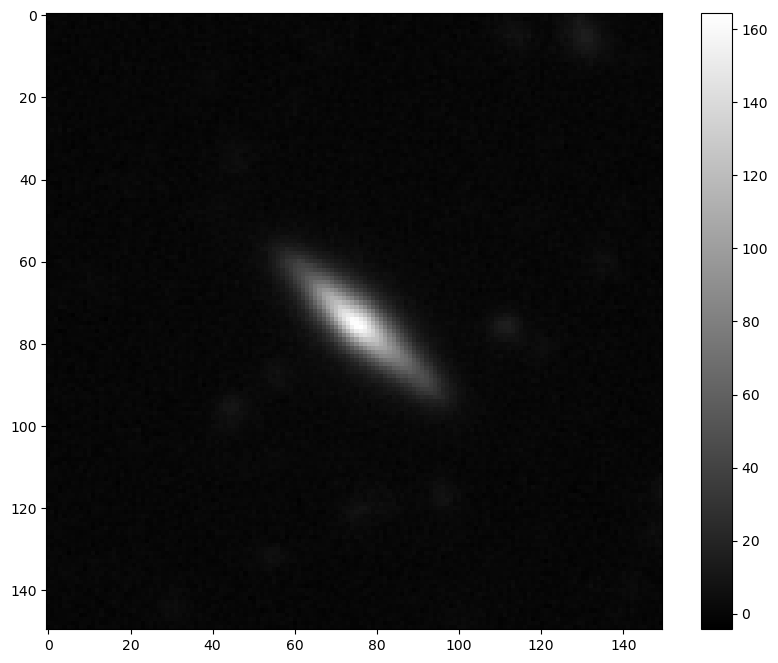

In [85]:
from astropy.io import fits
import matplotlib.pyplot as plt
import numpy as np
import sep
from matplotlib import rcParams

%matplotlib inline

rcParams['figure.figsize'] = [10., 8.]

# Open FITS file
hdul = fits.open("galaxy_images.fits")

# Image data
image = hdul[2].data
data = image.astype(image.dtype.newbyteorder('='))

# Show image
plt.imshow(data, cmap="gray")
plt.colorbar()
plt.show()

0.2642350494861603
1.1441140174865723


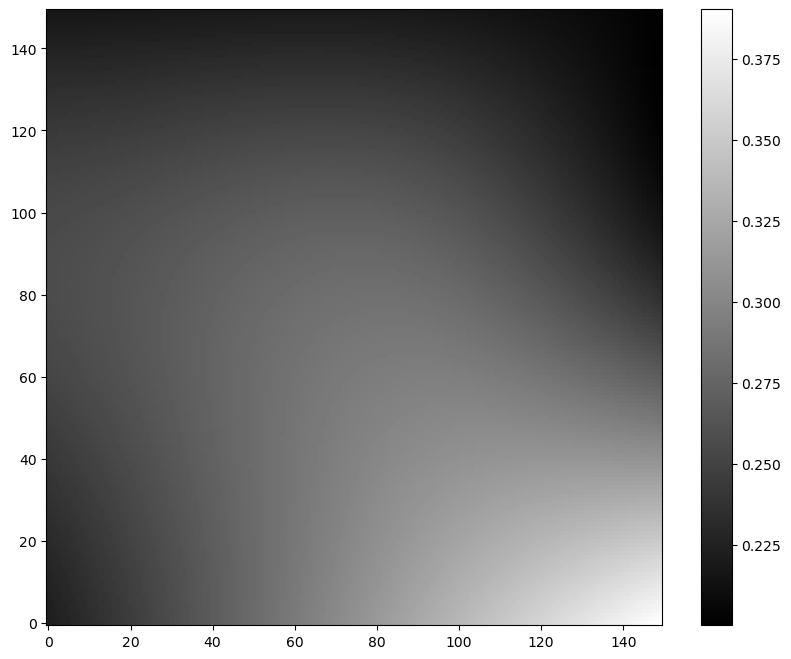

In [86]:
# measure a spatially varying background on the image
bkg = sep.Background(data)

# get a "global" mean and noise of the image background:
print(bkg.globalback)
print(bkg.globalrms)

# evaluate background as 2-d array, same size as original image
bkg_image = bkg.back()
# bkg_image = np.array(bkg) # equivalent to above

# show the background
plt.imshow(bkg_image, interpolation='nearest', cmap='gray', origin='lower')
plt.colorbar();

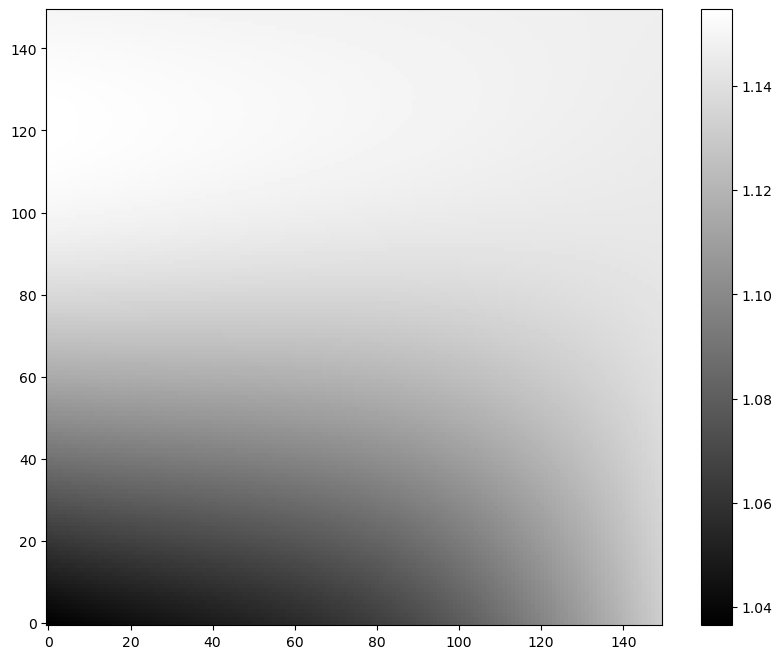

In [87]:
# evaluate the background noise as 2-d array, same size as original image
bkg_rms = bkg.rms()

# show the background noise
plt.imshow(bkg_rms, interpolation='nearest', cmap='gray', origin='lower')
plt.colorbar();

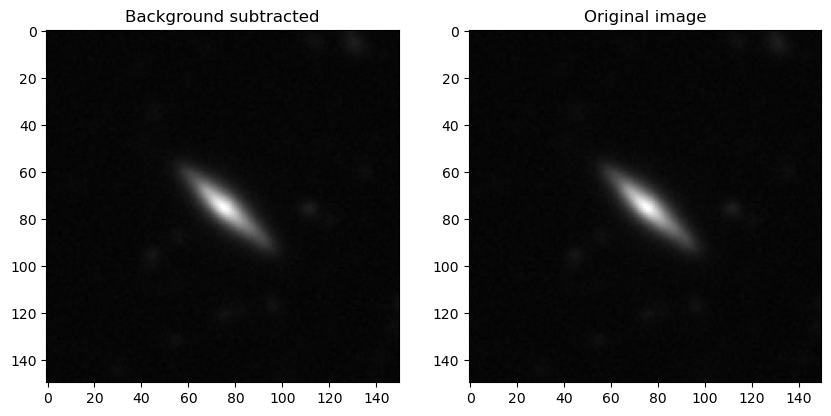

In [88]:
# subtract the background
data_sub = data - bkg

# Utwórz układ 1 wiersz, 2 kolumny
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# Lewy obraz
axes[0].imshow(data_sub, cmap="gray")
axes[0].set_title("Background subtracted")

# Prawy obraz
axes[1].imshow(data, cmap="gray")
axes[1].set_title("Original image")

plt.show()

In [89]:
objects = sep.extract(data_sub, 1.5, err=bkg.globalrms)

# how many objects were detected
len(objects)

14

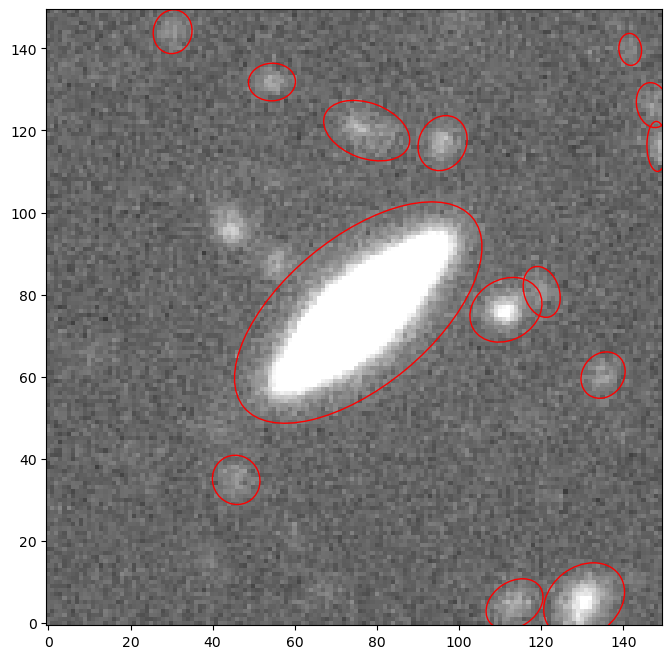

In [90]:
from matplotlib.patches import Ellipse

# plot background-subtracted image
fig, ax = plt.subplots()
m, s = np.mean(data_sub), np.std(data_sub)
im = ax.imshow(data_sub, interpolation='nearest', cmap='gray',
               vmin=m-s, vmax=m+s, origin='lower')

# plot an ellipse for each object
for i in range(len(objects)):
    e = Ellipse(xy=(objects['x'][i], objects['y'][i]),
                width=6*objects['a'][i],
                height=6*objects['b'][i],
                angle=objects['theta'][i] * 180. / np.pi)
    e.set_facecolor('none')
    e.set_edgecolor('red')
    ax.add_artist(e)

In [91]:
flux, fluxerr, flag = sep.sum_circle(data_sub, objects['x'], objects['y'],
                                     3.0, err=bkg.globalrms, gain=1.0)

# show the first 10 objects results:
for i in range(len(objects)):
    print(objects['x'][i], objects['y'][i])
    print("object {:d}: flux = {:f} +/- {:f}".format(i, flux[i], fluxerr[i]))

113.50229240351518 4.643245087558191
object 0: flux = 137.321433 +/- 13.209729
130.45280852095144 5.458021967777861
object 1: flux = 334.646104 +/- 19.281319
45.726242978548605 34.90544491833866
object 2: flux = 89.592308 +/- 11.254470
135.06471419571622 60.421821906118694
object 3: flux = 104.124076 +/- 11.873729
111.41245581928673 76.32891489384718
object 4: flux = 316.525799 +/- 18.801380
120.12256421261534 80.67977567347151
object 5: flux = 91.399111 +/- 11.334456
75.4442920798769 75.64844044625222
object 6: flux = 4138.377519 +/- 64.617709
148.1755958938091 116.1060063134081
object 7: flux = 76.250979 +/- 10.241671
95.98592261930905 116.90547477779357
object 8: flux = 152.753369 +/- 13.771967
77.50142872607746 119.94726282617944
object 9: flux = 125.694537 +/- 12.762055
147.1455329520872 126.16416282918858
object 10: flux = 74.702236 +/- 10.475256
54.441022284595576 131.78167412743733
object 11: flux = 114.407526 +/- 12.299141
141.67280552547774 139.73276535945666
object 12: flux 

flux = 162.358444 +/- 12.793258
flux = 444.089980 +/- 21.158989
flux = 1936.722208 +/- 44.192829
flux = 4101.012134 +/- 64.324270
flux = 6774.998809 +/- 82.706055
flux = 9660.344253 +/- 98.802706
flux = 12665.745427 +/- 113.193747
flux = 15624.161501 +/- 125.798552
flux = 18408.287505 +/- 136.641017
flux = 21051.703795 +/- 146.233517
flux = 23521.198760 +/- 154.696540
flux = 25821.854195 +/- 162.227478
flux = 27963.458449 +/- 168.979364
flux = 29938.843284 +/- 175.021896
flux = 31723.720851 +/- 180.356134
flux = 33372.346085 +/- 185.193561
flux = 34832.568018 +/- 189.429638
flux = 36177.585623 +/- 193.299615
flux = 37424.696725 +/- 196.866896
flux = 38550.325421 +/- 200.085362


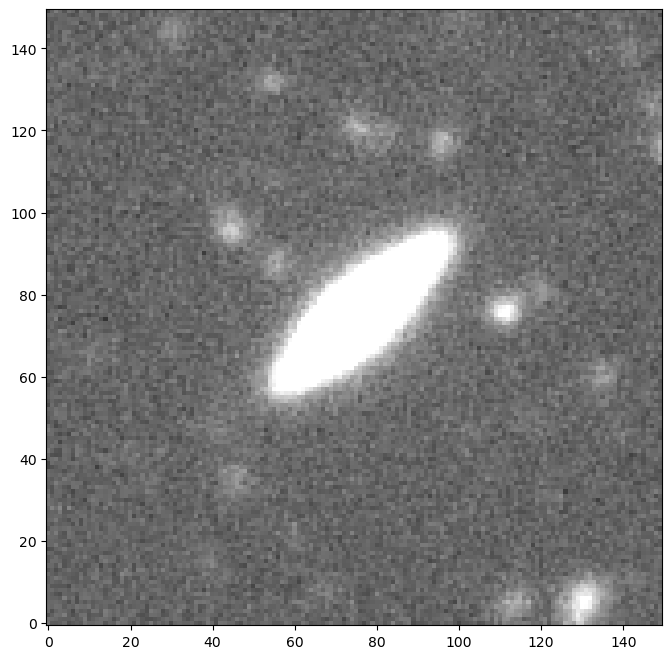

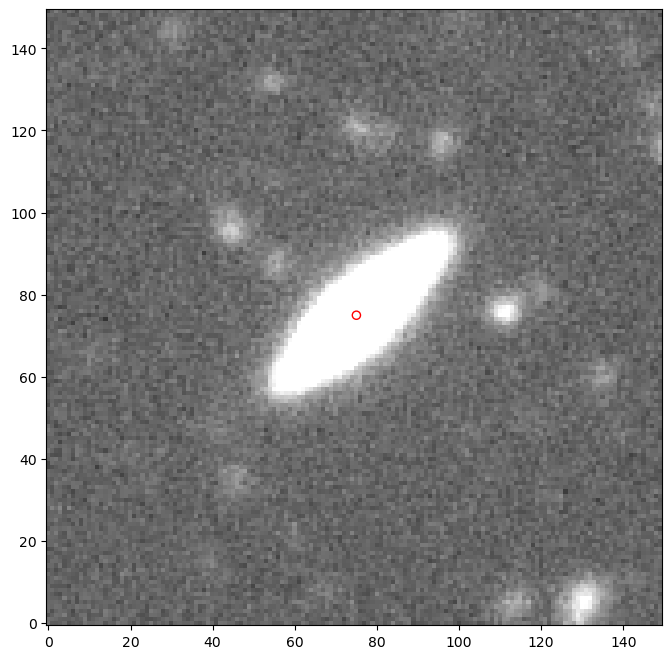

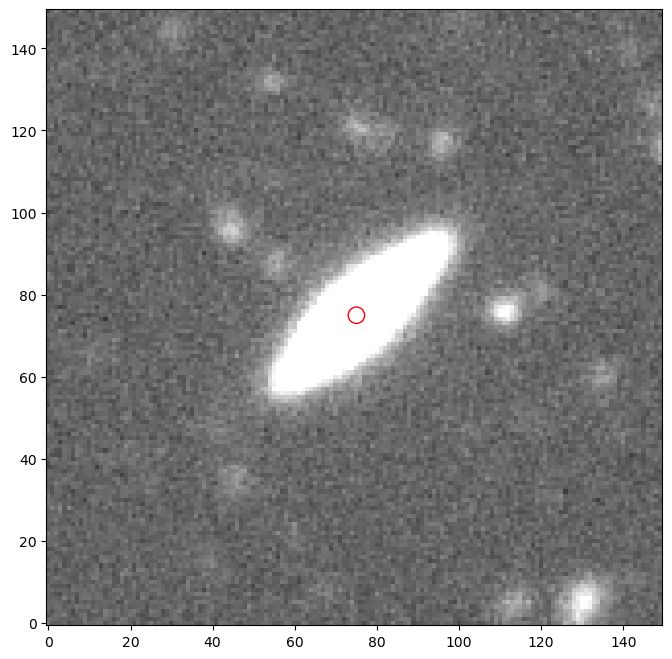

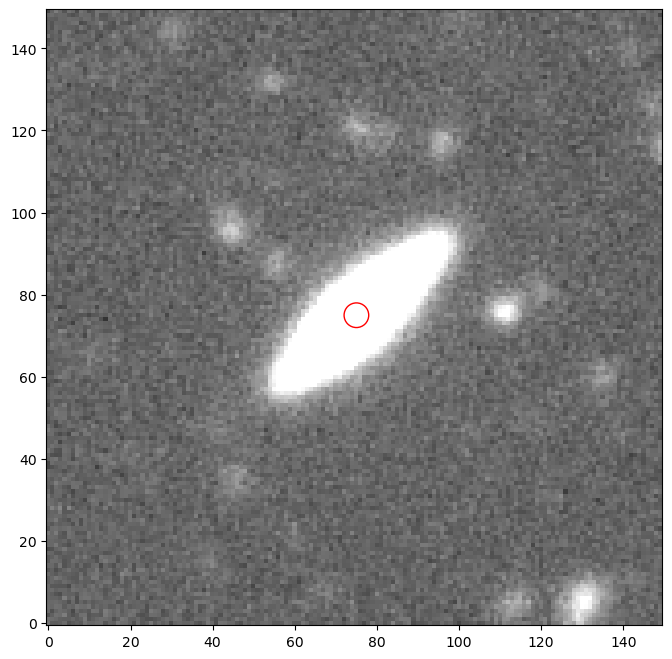

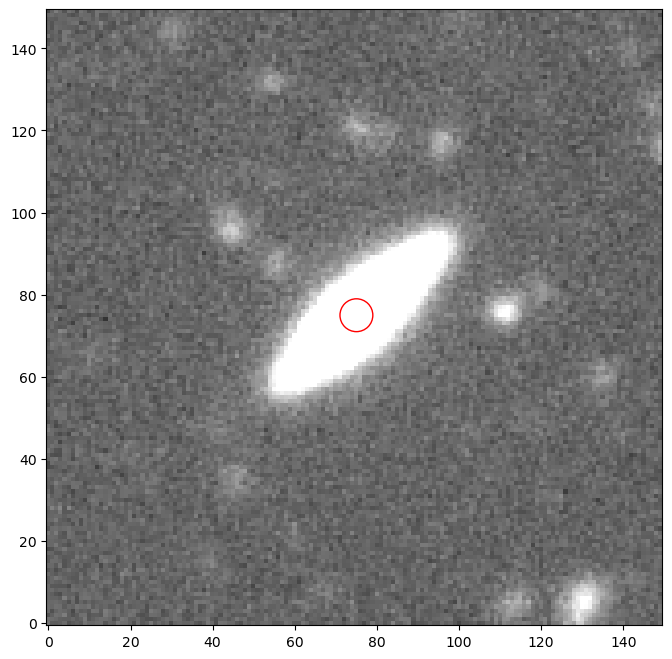

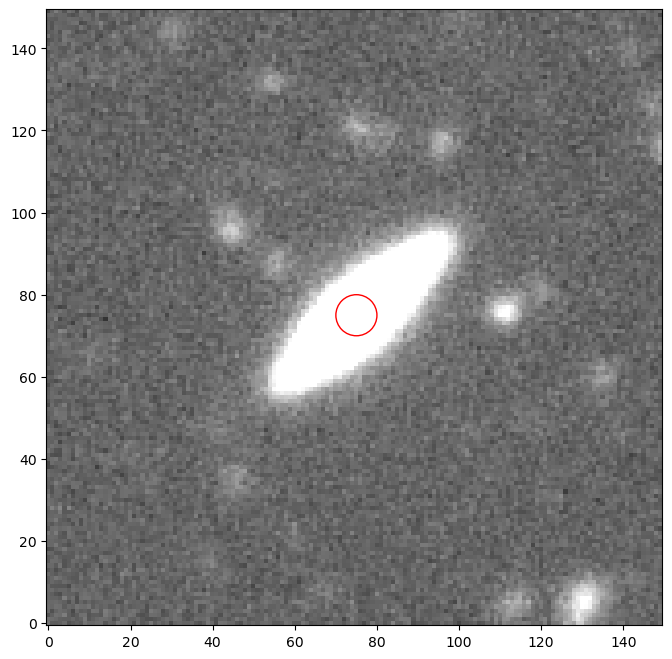

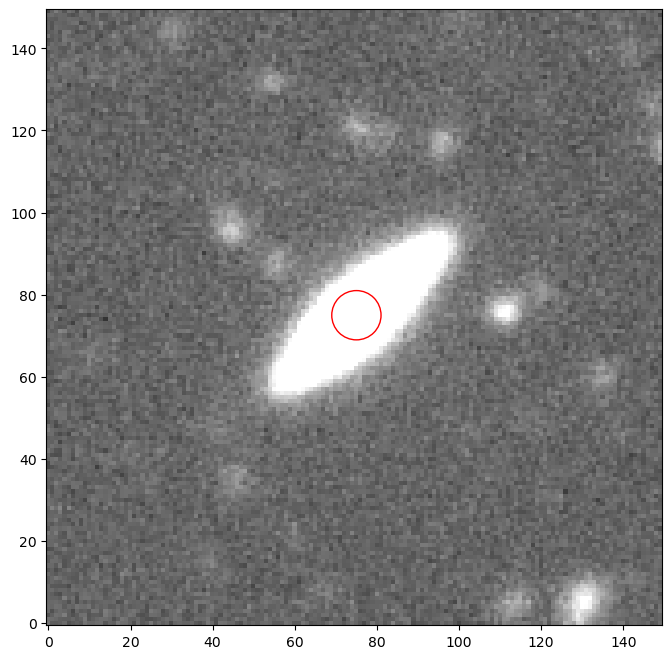

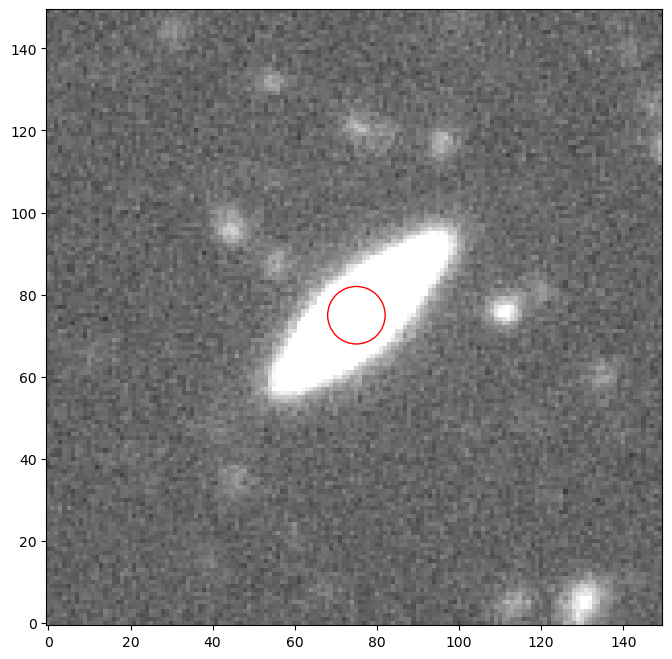

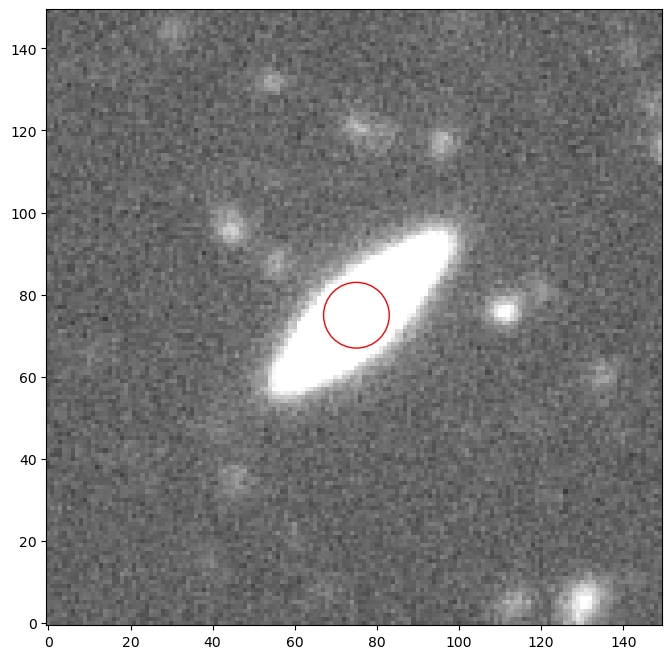

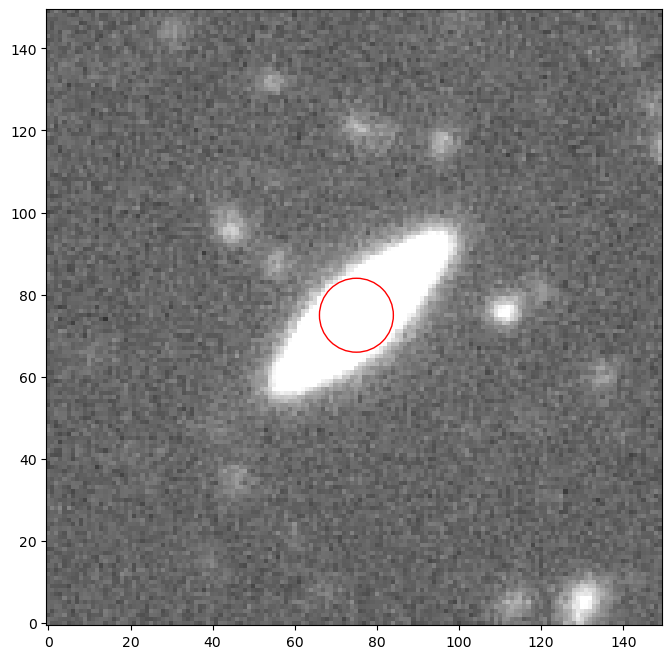

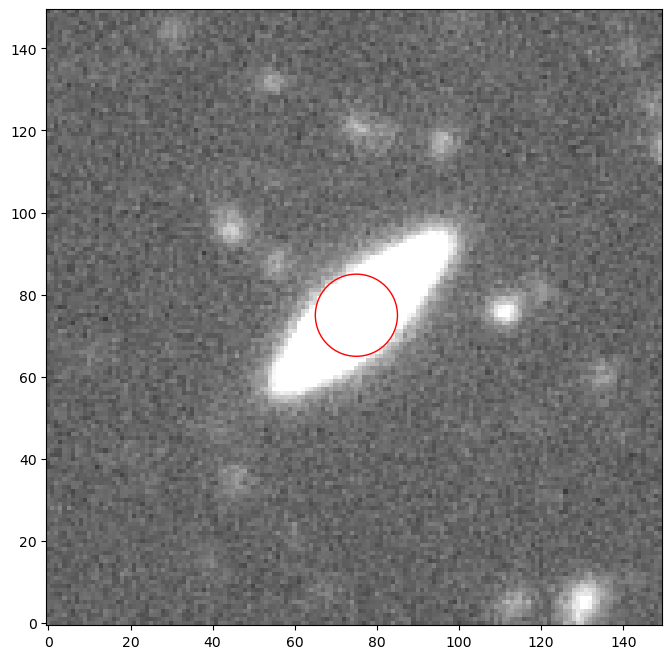

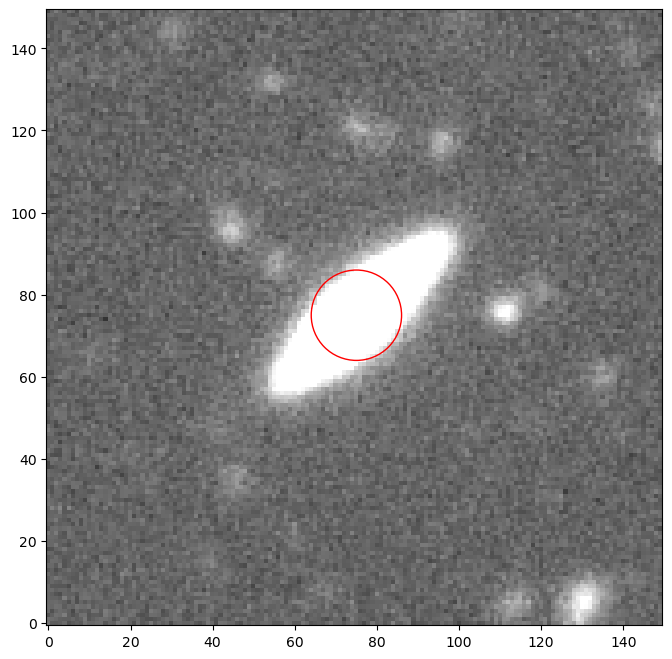

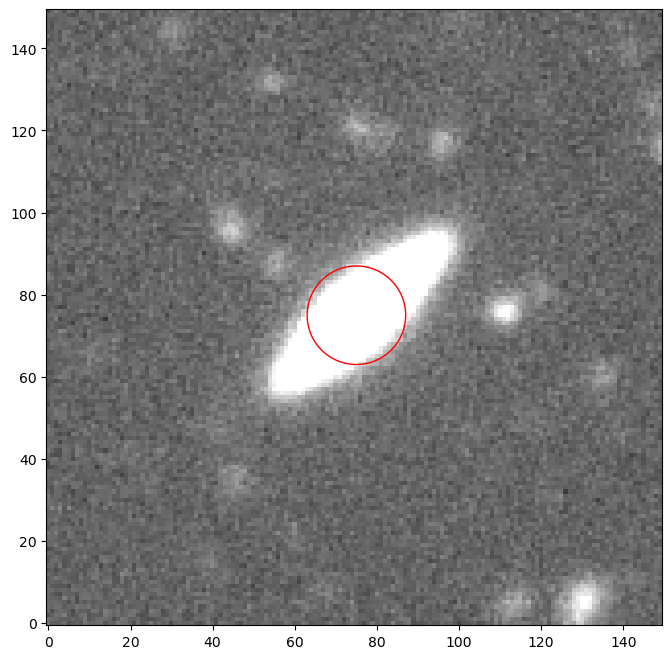

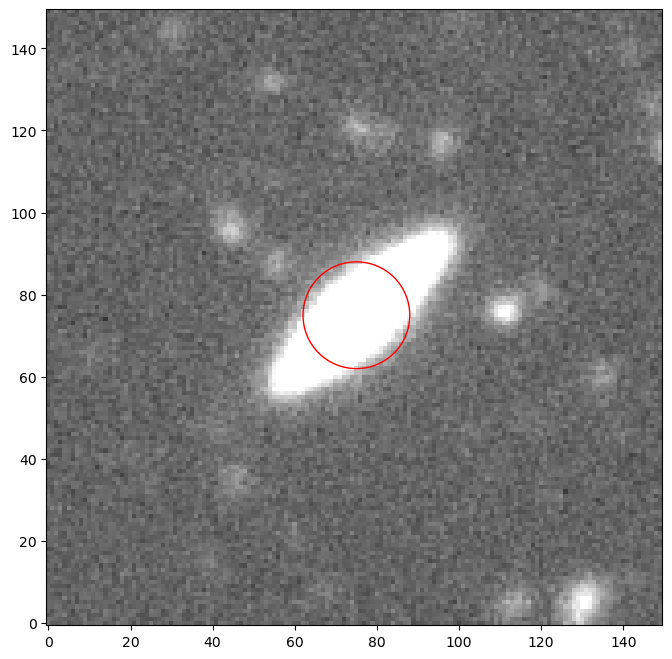

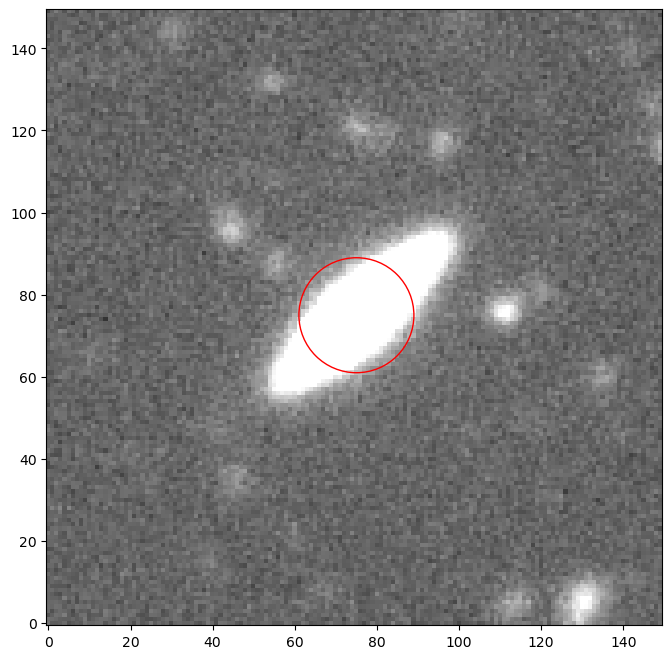

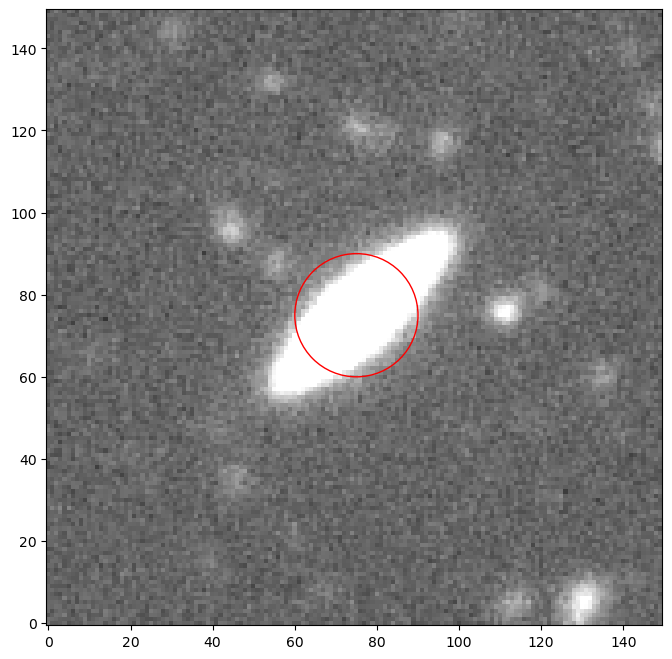

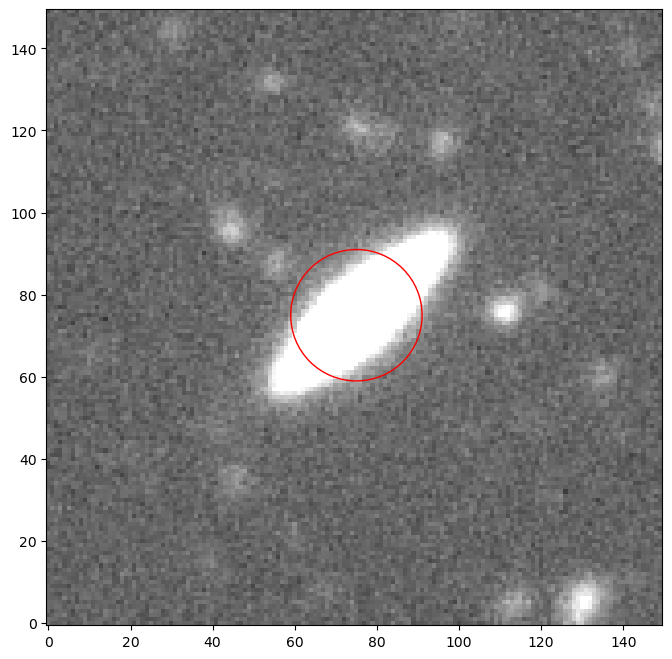

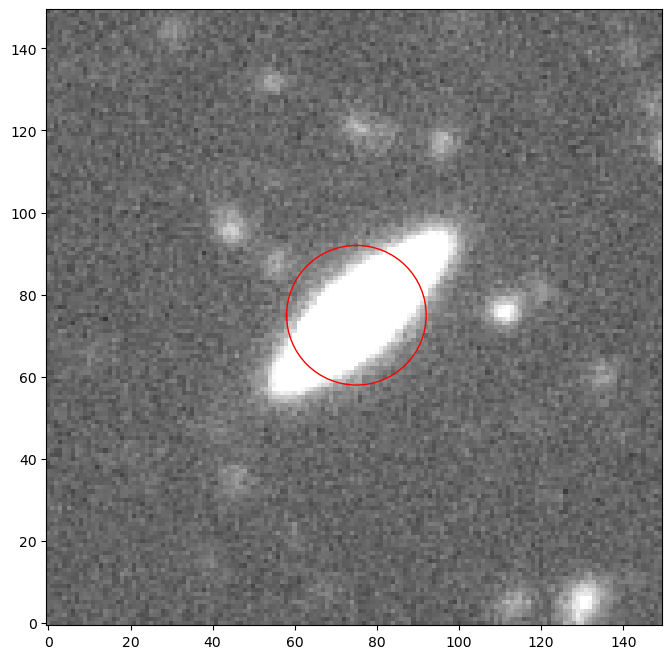

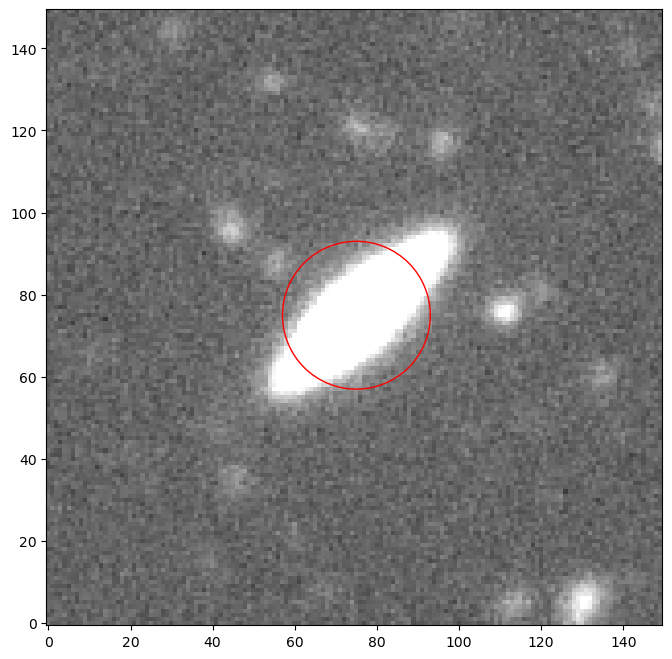

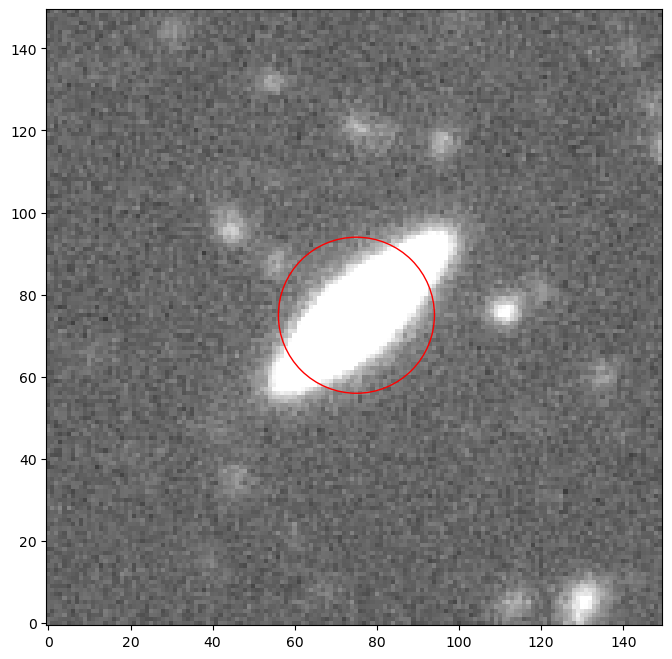

In [92]:
from matplotlib.patches import Circle

for i in range(20):
    flux, fluxerr, flag = sep.sum_circle(data_sub, x=[75.0], y=[75.0], 
                                        r=i, err=bkg.globalrms, gain=1.0)

    print("flux = {:f} +/- {:f}".format(flux[0], fluxerr[0]))

    fig, ax = plt.subplots()
    m, s = np.mean(data_sub), np.std(data_sub)
    im = ax.imshow(data_sub, interpolation='nearest', cmap='gray',
               vmin=m-s, vmax=m+s, origin='lower')

    e = Circle([75.0, 75.0],i)
    
    e.set_facecolor('none')
    e.set_edgecolor('red')
    ax.add_artist(e)

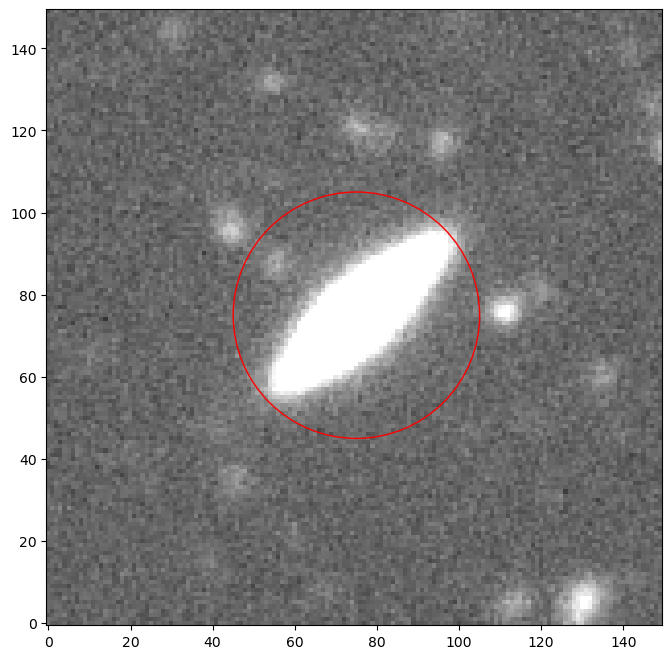

In [93]:
radius_range = 30

fig, ax = plt.subplots()
m, s = np.mean(data_sub), np.std(data_sub)
im = ax.imshow(data_sub, interpolation='nearest', cmap='gray',
            vmin=m-s, vmax=m+s, origin='lower')

c = Circle([75.0, 75.0],radius_range)

c.set_facecolor('none')
c.set_edgecolor('red')
ax.add_artist(c)

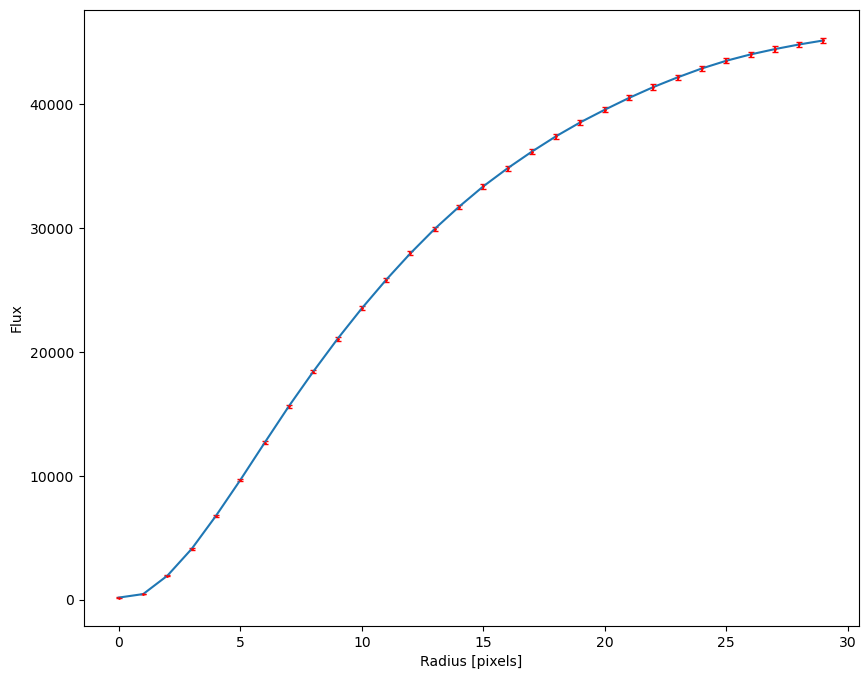

In [94]:
fluxes = np.zeros(radius_range)
fluxerrs = np.zeros(radius_range)
radiuses = np.zeros(radius_range)

for i in range(radius_range):
    flux, fluxerr, flag = sep.sum_circle(data_sub, x=[75.0], y=[75.0], 
                                        r=i, err=bkg.globalrms, gain=1.0)
    
    fluxes[i] = flux[0]
    fluxerrs[i] = fluxerr[0]
    radiuses[i] = i

plt.errorbar(
    x=radiuses, y=fluxes,
    yerr=fluxerrs,
    markersize=1,
    fmt='o',
    color ='red',
    capsize=2
)
plt.plot(radiuses, fluxes)       

plt.xlabel("Radius [pixels]")
plt.ylabel("Flux")
plt.show()

In [95]:
max_flux = fluxes[radius_range - 1]

print(f"Max flux = {max_flux}")

flux80 = 0.8 * max_flux
print(f"80% flux = {flux80}")

i = 0
while (fluxes[i] < flux80):
    i = i + 1

radius80 = i

print(f"Picked radius = {radius80}")

zp = 28.51 # dla filtru g dla gain = 1.0 ze stony LSST: https://smtn-002.lsst.io/

mag = -2.5 * np.log10(fluxes[radius80]) + zp
mag_err = (2.5 / np.log(10)) * (fluxerrs[radius80] / fluxes[radius80])

print(f"Galaxys flux in mag is {mag:.3f} \u00B1 {mag_err:.3f}")

Max flux = 45154.828957279315
80% flux = 36123.86316582345
Picked radius = 17
Galaxys flux in mag is 17.114 ± 0.006
